# 02 · Do customers come back?
Monthly cohorts by first purchase; a customer is a person (`customer_unique_id`).
Retention in month N = share of the cohort that placed a valid order N months after their first.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
from _common import ACCENT, MUTED, con

db = con()
db.sql("""
    select count(*) as customers,
           count(*) filter (where n_orders > 1) as repeat_customers,
           count(*) filter (where n_orders > 1) / count(*) as repeat_share
    from dim_customers
""").df()

,customers,repeat_customers,repeat_share
0,94983,2887,0.030395


In [2]:
db.sql("""
    select n_orders, count(*) as customers, count(*) / sum(count(*)) over () as share
    from dim_customers group by 1 order by 1
""").df()

,n_orders,customers,share
0,1,92096,0.969605
1,2,2651,0.027910
2,3,188,0.001979
3,4,29,0.000305
4,5,9,0.000095
5,6,5,0.000053
6,7,3,0.000032
7,9,1,0.000011
8,16,1,0.000011


## Retention curve (all cohorts in the analysis period, weighted by size)

In [3]:
curve = db.sql("""
    select months_since_first,
           sum(active_customers) / sum(cohort_size) as retention,
           sum(cohort_size) as customers_observed
    from mart_cohort_retention
    where is_analysis_period and months_since_first between 1 and 12
    group by 1 order by 1
""").df()
curve

,months_since_first,retention,customers_observed
0,1,0.004826,88484.0
1,2,0.003359,82467.0
2,3,0.002587,76547.0
3,4,0.002601,69961.0
4,5,0.002245,63263.0
5,6,0.002290,56332.0
6,7,0.002061,49976.0
7,8,0.002092,43025.0
8,9,0.001623,37588.0
9,10,0.002566,30400.0


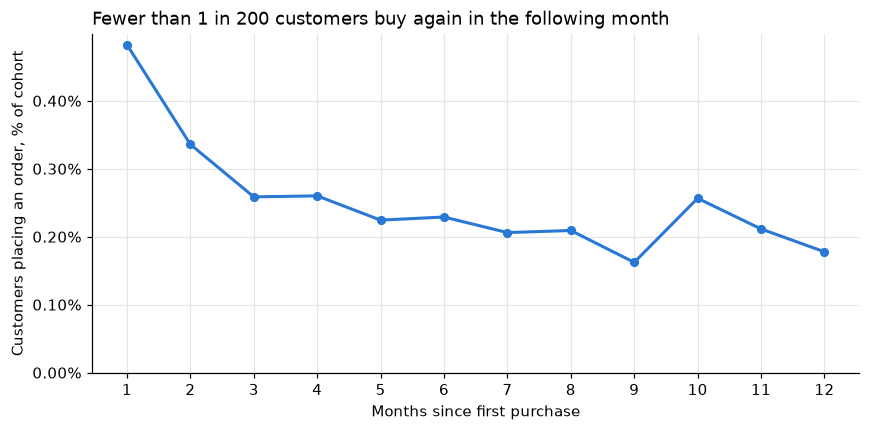

In [4]:
fig, ax = plt.subplots()
ax.plot(
    curve.months_since_first, curve.retention, color=ACCENT, linewidth=2, marker="o", markersize=5
)
ax.set_title("Fewer than 1 in 200 customers buy again in the following month")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Customers placing an order, % of cohort")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=2))
ax.set_ylim(bottom=0)
ax.set_xticks(range(1, 13))
plt.show()

## Cohort heatmap

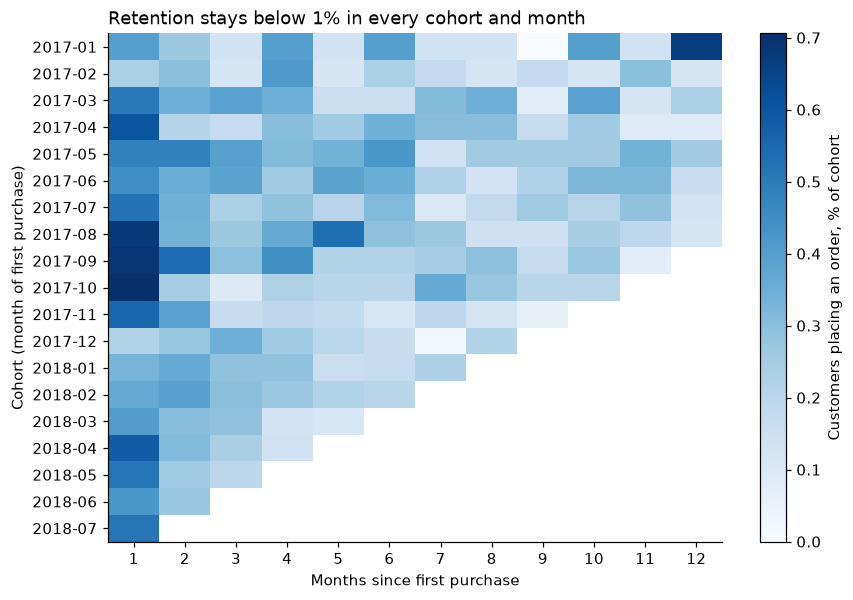

In [5]:
grid = (
    db.sql("""
        select strftime(cohort_month, '%Y-%m') as cohort, months_since_first, retention
        from mart_cohort_retention
        where is_analysis_period and months_since_first between 1 and 12
    """)
    .df()
    .pivot(index="cohort", columns="months_since_first", values="retention")
)
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(grid.values * 100, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (month of first purchase)")
ax.set_title("Retention stays below 1% in every cohort and month")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Customers placing an order, % of cohort")
plt.show()

## Why `customer_unique_id` matters
`customer_id` is generated per order, so grouping by it makes every customer look new.

In [6]:
db.sql("""
    select
        count(distinct customer_id) as customer_ids,
        count(distinct customer_unique_id) as people,
        count(*) filter (where n > 1) as ids_with_repeat_orders
    from (select customer_id, customer_unique_id, count(*) over (partition by customer_id) as n
          from fct_orders where is_valid_order)
""").df()

,customer_ids,people,ids_with_repeat_orders
0,98199,94983,0


## Time to second order

In [7]:
gaps = db.sql("""
    with o as (
        select customer_unique_id, purchased_at,
               row_number() over (partition by customer_unique_id order by purchased_at) as k
        from fct_orders where is_valid_order
    )
    select date_diff('day', a.purchased_at, b.purchased_at) as days
    from o a join o b on a.customer_unique_id = b.customer_unique_id and a.k = 1 and b.k = 2
""").df()
gaps.days.describe(percentiles=[0.25, 0.5, 0.75])

count    2887.000000
mean       80.792172
std       110.286019
min         0.000000
25%         0.000000
50%        28.000000
75%       125.000000
max       609.000000
Name: days, dtype: float64

Second orders placed on the same day as the first: 30%


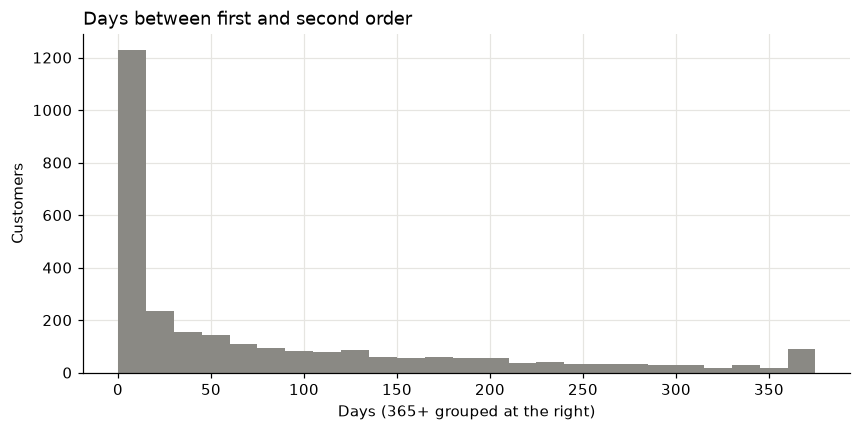

In [8]:
print(f"Second orders placed on the same day as the first: {np.mean(gaps.days == 0):.0%}")
fig, ax = plt.subplots()
ax.hist(gaps.days.clip(upper=365), bins=np.arange(0, 380, 15), color=MUTED)
ax.set_title("Days between first and second order")
ax.set_xlabel("Days (365+ grouped at the right)")
ax.set_ylabel("Customers")
plt.show()

## Findings
- **97% of customers bought exactly once** (92,096 of 94,983); only 2,887 people (3.0%) placed a second order.
- **Month-1 retention is 0.48%** and stays at 0.2–0.3% afterwards; no cohort exceeds 0.71% in any month.
- **30% of second orders are placed on the same day** as the first (median gap 28 days), so genuine
  return visits are rarer still.
- **Grouping by `customer_id` would hide even this**: 98,199 ids, none with a repeat order,
  versus 94,983 people.
- Growth therefore depends almost entirely on acquiring new customers; the second purchase is the
  largest untapped lever.